In [ ]:
import json, os, re, glob
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle

RUNS_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "runs", "mcp_runs"))
assert os.path.isdir(RUNS_DIR), RUNS_DIR


SURFACE, INK, SECOND, MUTED, GRID, AXIS = (
    "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7")

PHASE_COLOR = {"PROGRESSING": "#2a78d6", "STUCK": "#eb6834", "COMPLETED": "#1baf7a"}
PHASES = ["PROGRESSING", "STUCK", "COMPLETED"]

COND_ORDER = ["baseline", "broken"]
COND_COLOR = {"baseline": "#2a78d6", "broken": "#e34948"}

MODEL_ORDER = ["gpt-5-nano", "gpt-5.6-luna", "gpt-5.6-terra", "gpt-5.6-sol"]
MODEL_COLOR = dict(zip(MODEL_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#b25fd3"]))


TOOL_ORDER = ["tavily_search", "tavily_research", "tavily_extract",
              "tavily_crawl", "tavily_map"]
TOOL_COLOR = dict(zip(TOOL_ORDER,
                      ["#a9b6c4", "#2a78d6", "#1baf7a", "#eb6834", "#b25fd3"]))

FAULT_COLOR = {False: "#2a78d6", True: "#e34948"}

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": SECOND, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "figure.dpi": 110, "lines.linewidth": 2,
})

def tidy(ax, grid_axis="y"):
    ax.grid(True, axis=grid_axis, zorder=0)
    ax.set_axisbelow(True)
    return ax

def short(run):
    # batch1-1-broken-gpt-5.6-sol-... -> b1-1 broken
    b, t, cond = run.split("-")[0], run.split("-")[1], run.split("-")[2]
    return f"{b.replace('batch', 'b')}-{t} {cond}"

In [ ]:
MODELS = ["gpt-5.6-luna", "gpt-5.6-terra", "gpt-5.6-sol", "gpt-5-nano"]
CONDITIONS = ["baseline", "broken"]
EFFORTS = ["low", "medium", "high", "max"]


_RUN_RE = re.compile(
    r"^batch(?P<batch>\d+)-(?P<trial>\d+)-(?P<condition>" + "|".join(CONDITIONS) + r")"
    r"-(?P<models>.+)-(?P<effort>" + "|".join(EFFORTS) + r")"
    r"-(?P<topos>topos|notopos)-(?P<date>\d{8})-(?P<time>\d{6})$")

def parse_run_id(name):
    m = _RUN_RE.match(name)
    if not m:
        raise ValueError(f"unparseable run id: {name}")
    mid = m.group("models")
    for agent in sorted(MODELS, key=len, reverse=True):
        if mid.startswith(agent + "-") and mid[len(agent) + 1:] in MODELS:
            monitor = mid[len(agent) + 1:]
            break
    else:
        raise ValueError(f"unparseable model pair: {mid}")
    return dict(run=name, batch=int(m.group("batch")), trial=int(m.group("trial")),
                condition=m.group("condition"), agent_model=agent,
                monitor_model=monitor, effort=m.group("effort"),
                topos=(m.group("topos") == "topos"),
                started=m.group("date") + "-" + m.group("time"))


HEDGE_RE = re.compile(
    r"limited progress|little progress|slow progress|repeat|repetiti|"
    r"no convergence|not converging|circular|loop(?:ing)?\b|redundan|"
    r"marginal|stalling|stagnat|diminishing", re.I)

def load(runs_dir=RUNS_DIR):
    run_rows, step_rows, call_rows = [], [], []
    for d in sorted(glob.glob(os.path.join(runs_dir, "batch*", "batch*"))):
        meta = parse_run_id(os.path.basename(d))
        name = meta["run"]
        path = os.path.join(d, "results.jsonl")
        if not os.path.exists(path):
            run_rows.append({**meta, "present": False, "n_steps": 0,
                             "mcp_call_count": 0, "stuck_share": np.nan})
            continue
        rec = [json.loads(l) for l in open(path) if l.strip()][0]
        ph = rec.get("phase_history") or []
        alog, slog = rec.get("analysis_log") or [], rec.get("summary_log") or []
        clog = rec.get("mcp_call_log") or []
        counts = rec.get("mcp_tool_counts") or {}

        body = [p for p in ph if p != "COMPLETED"]   # the end marker is not a step
        n_calls = len(clog)
        n_faulted = sum(bool(c.get("faulted")) for c in clog)
        run_rows.append({
            **meta, "present": True, "question_id": rec.get("question_id"),
            "question_title": rec.get("question_title"),
            "n_steps": len(ph), "n_body_steps": len(body),
            "final_phase": rec.get("final_phase"),
            "n_stuck": sum(p == "STUCK" for p in body),
            "stuck_share": (sum(p == "STUCK" for p in body) / len(body)) if body else np.nan,
            "n_completed_labels": sum(p == "COMPLETED" for p in ph),
            "answer_len": len(rec.get("agent_answer") or ""),
            "mcp_call_count": rec.get("mcp_call_count", n_calls),
            "mcp_faulted_count": rec.get("mcp_faulted_count", n_faulted),
            "faulted_share": (n_faulted / n_calls) if n_calls else np.nan,
            **{t: int(counts.get(t, 0)) for t in TOOL_ORDER},
        })
        for i, phase in enumerate(ph):
            step_rows.append({
                **meta, "i": i, "n_steps": len(ph),
                "pos": i / (len(ph) - 1) if len(ph) > 1 else 0.0,
                "phase": phase,
                "next_phase": ph[i + 1] if i + 1 < len(ph) else None,
                "justification": alog[i] if i < len(alog) else "",
                "summary": slog[i] if i < len(slog) else "",
                "hedged": bool(HEDGE_RE.search(alog[i] if i < len(alog) else "")),
            })
        for c in clog:
            j = c["index"] - 1
            call_rows.append({
                **meta, "index": c["index"], "j": j, "n_calls": n_calls,
                "pos": j / (n_calls - 1) if n_calls > 1 else 0.0,
                "tool": c["tool"], "faulted": bool(c.get("faulted")),
                "arguments": c.get("arguments", ""),
            })

    runs = pd.DataFrame(run_rows).sort_values(["batch", "trial"]).reset_index(drop=True)
    steps, calls = pd.DataFrame(step_rows), pd.DataFrame(call_rows)
    for df in (runs, steps, calls):
        df["condition"] = pd.Categorical(df["condition"], COND_ORDER, ordered=True)
    steps["is_body"] = steps["phase"] != "COMPLETED"
    return runs, steps, calls

runs, steps, calls = load()
ok = runs[runs.n_steps > 0]           
body = steps[steps.is_body]       


assert len(calls) == int(runs.mcp_call_count.sum()), "call frame lost rows"
for d in sorted(glob.glob(os.path.join(RUNS_DIR, "batch*", "batch*"))):
    rec = [json.loads(l) for l in open(os.path.join(d, "results.jsonl")) if l.strip()][0]
    assert rec["tool_call"] == [c["tool"] for c in rec["mcp_call_log"]], d

print(f"{len(runs)} cells parsed | {runs.present.sum()} with a results file "
      f"| {len(ok)} with monitor steps | {len(steps)} steps | {len(calls)} mcp calls")
print("faulted_share values:", sorted(runs.faulted_share.dropna().unique()))
runs[["run", "batch", "trial", "condition", "agent_model", "monitor_model", "effort",
      "n_steps", "n_stuck", "stuck_share", "final_phase", "mcp_call_count",
      "mcp_faulted_count", "faulted_share", "answer_len"]]

6 cells parsed | 6 with a results file | 6 with monitor steps | 102 steps | 119 mcp calls
faulted_share values: [np.float64(0.0), np.float64(1.0)]


,run,batch,trial,condition,agent_model,monitor_model,effort,n_steps,n_stuck,stuck_share,final_phase,mcp_call_count,mcp_faulted_count,faulted_share,answer_len
0,batch1-0-baseline-gpt-5.6-sol-gpt-5.6-sol-max-...,1,0,baseline,gpt-5.6-sol,gpt-5.6-sol,max,13,4,0.333333,COMPLETED,31,0,0.0,0
1,batch1-1-broken-gpt-5.6-sol-gpt-5.6-sol-max-no...,1,1,broken,gpt-5.6-sol,gpt-5.6-sol,max,19,0,0.000000,COMPLETED,18,18,1.0,0
2,batch2-0-baseline-gpt-5.6-terra-gpt-5.6-terra-...,2,0,baseline,gpt-5.6-terra,gpt-5.6-terra,max,9,4,0.500000,COMPLETED,31,0,0.0,0
3,batch2-1-broken-gpt-5.6-terra-gpt-5.6-terra-ma...,2,1,broken,gpt-5.6-terra,gpt-5.6-terra,max,20,4,0.210526,COMPLETED,19,19,1.0,0
4,batch3-0-baseline-gpt-5-nano-gpt-5.6-terra-hig...,3,0,baseline,gpt-5-nano,gpt-5.6-terra,high,13,0,0.000000,COMPLETED,10,0,0.0,0
5,batch3-1-broken-gpt-5-nano-gpt-5.6-terra-high-...,3,1,broken,gpt-5-nano,gpt-5.6-terra,high,28,12,0.444444,COMPLETED,10,10,1.0,0


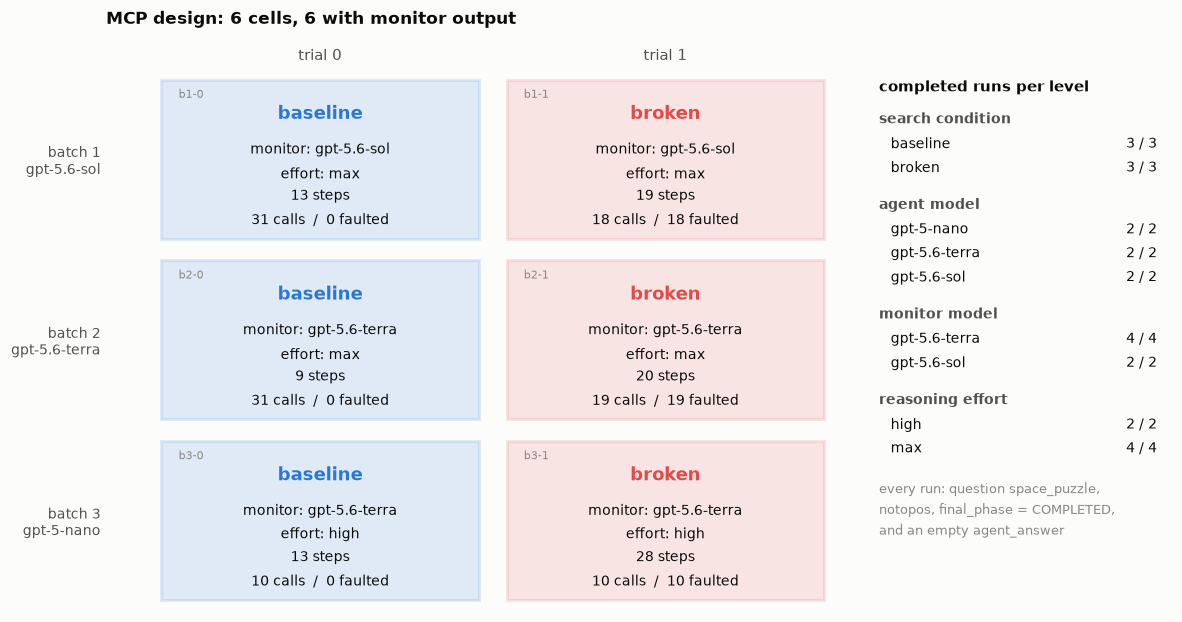

In [3]:
NB, NT = runs.batch.nunique(), runs.trial.nunique()
fig = plt.figure(figsize=(12.5, 6.4))
gs = fig.add_gridspec(1, 2, width_ratios=[2.5, 1.0], wspace=0.08)
ax, axt = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

for r in runs.itertuples():
    x, y = r.trial, r.batch - 1
    usable = r.n_steps > 0
    c = COND_COLOR[r.condition] if usable else MUTED
    ax.add_patch(Rectangle((x + .04, y + .06), .92, .88, facecolor=c,
                           alpha=.13 if usable else .10, edgecolor=c,
                           linewidth=2 if usable else 1,
                           linestyle="-" if usable else (0, (4, 3)), zorder=2))
    ax.text(x + .5, y + .25, r.condition, ha="center", va="center", zorder=3,
            fontsize=12, fontweight="bold", color=c if usable else MUTED)
    if usable:
        lines = [f"monitor: {r.monitor_model}",
                 f"effort: {r.effort}",
                 f"{r.n_steps} steps",
                 f"{int(r.mcp_call_count)} calls  /  {int(r.mcp_faulted_count)} faulted"]
    elif r.present:
        lines = ["answer written, but", "NO monitor output", "0 steps", ""]
    else:
        lines = ["no results.jsonl", "(empty directory)", "", ""]
    ax.text(x + .5, y + .64, "\n".join(lines), ha="center", va="center", zorder=3,
            fontsize=9, color=INK if usable else MUTED, linespacing=1.7)
    ax.text(x + .09, y + .16, f"b{r.batch}-{r.trial}", fontsize=7.5, color=MUTED, zorder=3)

ax.set_xlim(-.12, NT); ax.set_ylim(NB, 0)
ax.set_xticks([i + .5 for i in range(NT)])
ax.set_xticklabels([f"trial {i}" for i in range(NT)], fontsize=10, color=SECOND)
ax.xaxis.set_ticks_position("top"); ax.xaxis.set_label_position("top")
ax.set_yticks([i + .5 for i in range(NB)])
ax.set_yticklabels([f"batch {i+1}\n{runs[runs.batch==i+1].agent_model.iloc[0]}"
                    for i in range(NB)], fontsize=9, color=SECOND)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)
ax.set_title(f"MCP design: {len(runs)} cells, {len(ok)} with monitor output",
             pad=16, loc="left")

axt.axis("off")
y = 0.98
axt.text(0, y, "completed runs per level", fontsize=10, fontweight="bold",
         va="top", color=INK); y -= 0.06
for label, col in [("search condition", "condition"), ("agent model", "agent_model"),
                   ("monitor model", "monitor_model"), ("reasoning effort", "effort")]:
    axt.text(0, y, label, fontsize=9, fontweight="bold", va="top", color=SECOND)
    y -= 0.046
    counts, allc = ok[col].value_counts(), runs[col].value_counts()
    levels = (COND_ORDER if col == "condition" else
              [m for m in MODEL_ORDER if allc.get(m, 0)] if "model" in col else
              [e for e in EFFORTS if allc.get(e, 0)])
    for lvl in levels:
        n, N = int(counts.get(lvl, 0)), int(allc.get(lvl, 0))
        axt.text(0.04, y, f"{lvl}", fontsize=9, va="top", color=INK)
        axt.text(0.95, y, f"{n} / {N}", fontsize=9, va="top", ha="right",
                 color=INK if n == N else "#d03b3b")
        y -= 0.044
    y -= 0.024
axt.text(0, y, "every run: question space_puzzle,\nnotopos, final_phase = COMPLETED,\n"
                "and an empty agent_answer",
         fontsize=8.5, va="top", color=MUTED, linespacing=1.6)
plt.show()

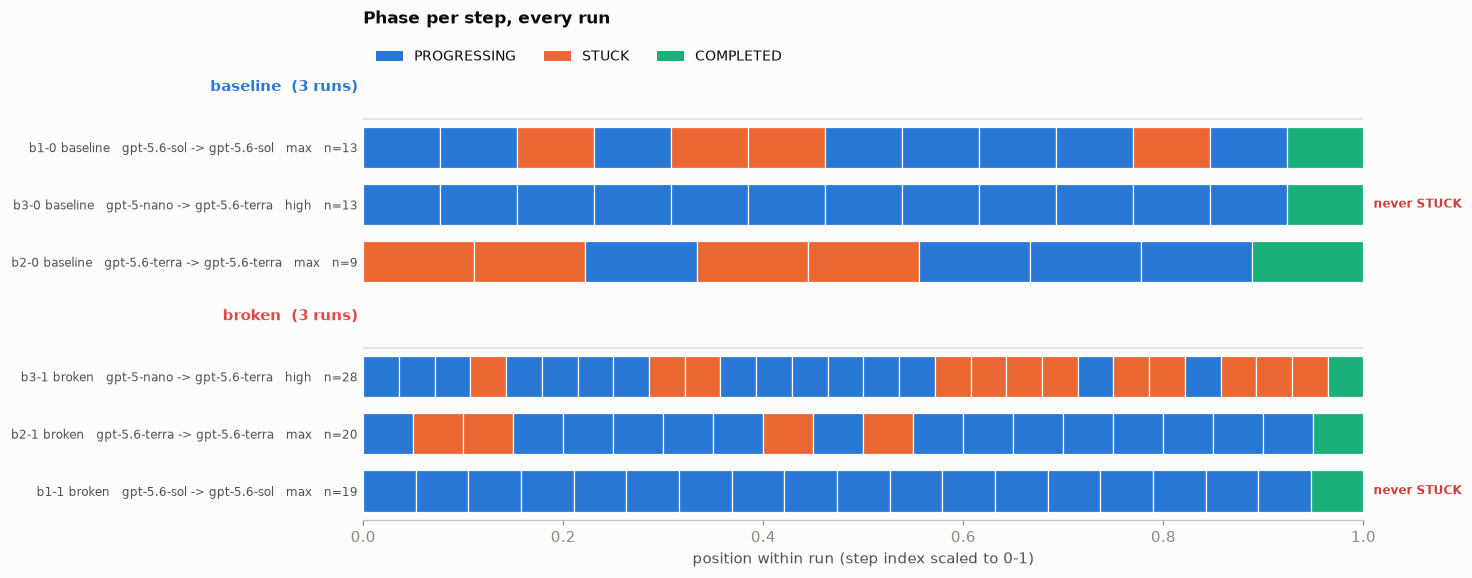

In [4]:
order = [(cond, list(runs[runs.condition == cond]
                     .sort_values("n_steps", ascending=False).itertuples()))
         for cond in COND_ORDER]

nrows = len(runs) + len(COND_ORDER)
fig, ax = plt.subplots(figsize=(13.5, 0.42 * nrows + 2.0))
y, yticks, ylabels, seps = 0, [], [], []
for cond, rows in order:
    seps.append((y - 0.5, cond, len(rows)))
    for r in rows:
        if r.n_steps > 0:
            ph = steps[steps.run == r.run].sort_values("i")
            w = 1.0 / r.n_steps
            ax.broken_barh([(i * w, w) for i in ph.i], (y - .36, .72),
                           facecolors=[PHASE_COLOR[p] for p in ph.phase],
                           edgecolor=SURFACE, linewidth=0.8, zorder=2)
            notes = []
            if r.n_completed_labels > 1:
                notes.append(f"{int(r.n_completed_labels)}x COMPLETED")
            if r.final_phase != "COMPLETED":
                notes.append(f"final_phase={r.final_phase}")
            if r.n_stuck == 0:
                notes.append("never STUCK")
            if notes:
                ax.text(1.01, y, " | ".join(notes), va="center", fontsize=8,
                        color="#d03b3b", fontweight="bold")
        else:
            ax.broken_barh([(0, 1)], (y - .36, .72), facecolors="none",
                           edgecolor=MUTED, linewidth=1, hatch="///", zorder=2)
            ax.text(1.01, y, "no monitor output", va="center", fontsize=8,
                    color="#d03b3b", fontweight="bold")
        yticks.append(y)
        ylabels.append(f"{short(r.run)}   {r.agent_model} -> {r.monitor_model}   "
                       f"{r.effort}   n={r.n_steps}")
        y += 1
    y += 1

for ypos, cond, n in seps:
    ax.axhline(ypos, color=GRID, linewidth=1, zorder=1)
    ax.text(-0.005, ypos - 0.55, f"{cond}  ({n} runs)", ha="right", va="center",
            fontsize=10, fontweight="bold", color=COND_COLOR[cond])
ax.set_yticks(yticks); ax.set_yticklabels(ylabels, fontsize=8, color=SECOND)
ax.tick_params(axis="y", length=0)
ax.set_ylim(y - 1.5, -1.2)
ax.set_xlim(0, 1); ax.set_xlabel("position within run (step index scaled to 0-1)")
ax.spines["left"].set_visible(False)
ax.set_title("Phase per step, every run", loc="left", pad=36)
ax.legend(handles=[Patch(facecolor=PHASE_COLOR[p], label=p) for p in PHASES],
          loc="lower left", bbox_to_anchor=(0, 1.005), ncol=3, frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

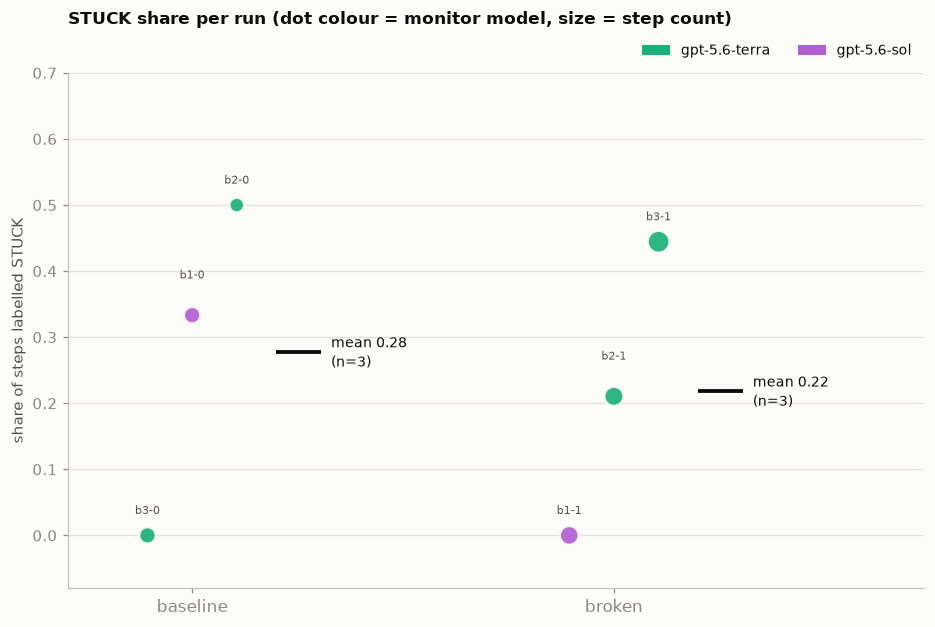

           runs  mean_stuck  runs_with_zero_stuck
condition                                        
baseline      3    0.277778                     1
broken        3    0.218324                     1


In [ ]:
d = ok.dropna(subset=["stuck_share"])
fig, ax = plt.subplots(figsize=(8.6, 5.8))
XSTEP = 1.7
for k_, cond in enumerate(COND_ORDER):
    i = k_ * XSTEP
   
    g = d[d.condition == cond].sort_values("stuck_share")
    off = np.linspace(-.18, .18, len(g)) if len(g) > 1 else np.array([0.0])
    ax.scatter(i + off, g.stuck_share, s=40 + g.n_steps * 6,
               c=[MODEL_COLOR[m] for m in g.monitor_model],
               edgecolor=SURFACE, linewidth=1.6, zorder=3, alpha=.92)
    for k, (x, yv, r) in enumerate(zip(i + off, g.stuck_share, g.itertuples())):
        ax.annotate(short(r.run).split()[0], (x, yv), textcoords="offset points",
                    xytext=(0, 14 + 10 * (k % 2)), ha="center", fontsize=7.5,
                    color=SECOND, zorder=4)
    m = g.stuck_share.mean()
    ax.hlines(m, i + .34, i + .52, color=INK, linewidth=2.5, zorder=5)
    ax.text(i + .56, m, f"mean {m:.2f}\n(n={len(g)})", ha="left", va="center",
            fontsize=9, color=INK, zorder=6, linespacing=1.4)
tidy(ax)
ax.set_xticks([k_ * XSTEP for k_ in range(len(COND_ORDER))])
ax.set_xticklabels(COND_ORDER, fontsize=11)
ax.set_xlim(-.5, (len(COND_ORDER) - 1) * XSTEP + 1.25); ax.set_ylim(-.08, .70)
ax.set_ylabel("share of steps labelled STUCK")
ax.set_title("STUCK share per run (dot colour = monitor model, size = step count)",
             loc="left", pad=32)
ax.legend(handles=[Patch(facecolor=MODEL_COLOR[m], label=m) for m in MODEL_ORDER
                   if (ok.monitor_model == m).any()],
          loc="lower right", bbox_to_anchor=(1, 1.005), ncol=3, frameon=False,
          fontsize=9)
plt.tight_layout(); plt.show()

print(d.groupby("condition", observed=True)
       .agg(runs=("run", "size"), mean_stuck=("stuck_share", "mean"),
            runs_with_zero_stuck=("n_stuck", lambda s: int((s == 0).sum()))))

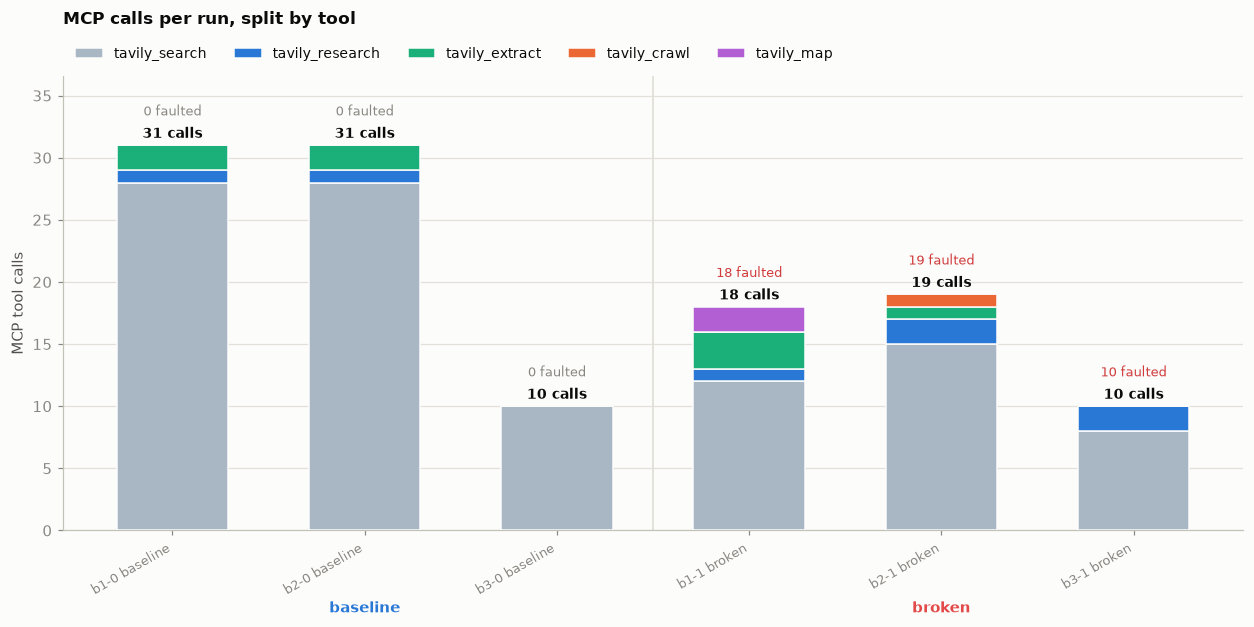

                                                   condition  mcp_call_count  \
run                                                                            
batch1-0-baseline-gpt-5.6-sol-gpt-5.6-sol-max-n...  baseline              31   
batch2-0-baseline-gpt-5.6-terra-gpt-5.6-terra-m...  baseline              31   
batch3-0-baseline-gpt-5-nano-gpt-5.6-terra-high...  baseline              10   
batch1-1-broken-gpt-5.6-sol-gpt-5.6-sol-max-not...    broken              18   
batch2-1-broken-gpt-5.6-terra-gpt-5.6-terra-max...    broken              19   
batch3-1-broken-gpt-5-nano-gpt-5.6-terra-high-n...    broken              10   

                                                    mcp_faulted_count  \
run                                                                     
batch1-0-baseline-gpt-5.6-sol-gpt-5.6-sol-max-n...                  0   
batch2-0-baseline-gpt-5.6-terra-gpt-5.6-terra-m...                  0   
batch3-0-baseline-gpt-5-nano-gpt-5.6-terra-high...                 

In [6]:
d = runs.sort_values(["condition", "batch"]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11.5, 5.8))
xs = np.arange(len(d))
bot = np.zeros(len(d))
for tool in TOOL_ORDER:
    v = d[tool].values.astype(float)
    ax.bar(xs, v, .58, bottom=bot, color=TOOL_COLOR[tool], edgecolor=SURFACE,
           linewidth=1, zorder=3, label=tool)
    bot += v
for i, r in enumerate(d.itertuples()):
    ax.text(i, bot[i] + .6, f"{int(r.mcp_call_count)} calls", ha="center",
            fontsize=9, color=INK, fontweight="bold")
    ax.text(i, bot[i] + 2.4, f"{int(r.mcp_faulted_count)} faulted", ha="center",
            fontsize=8.5,
            color="#d03b3b" if r.mcp_faulted_count else MUTED)
for i in range(1, len(d)):
    if d.condition[i] != d.condition[i - 1]:
        ax.axvline(i - .5, color=GRID, linewidth=1.2, zorder=1)
for cond in COND_ORDER:
    idx = [i for i in range(len(d)) if d.condition[i] == cond]
    ax.annotate(cond, xy=(np.mean(idx), 0), xycoords=("data", "axes fraction"),
                xytext=(0, -46), textcoords="offset points", ha="center", va="top",
                fontsize=10, color=COND_COLOR[cond], fontweight="bold",
                annotation_clip=False)
tidy(ax)
ax.set_xticks(xs); ax.set_xticklabels([short(r) for r in d.run], rotation=30,
                                      ha="right", fontsize=8.5)
ax.set_ylabel("MCP tool calls")
ax.set_ylim(0, bot.max() * 1.18)
ax.set_title("MCP calls per run, split by tool", loc="left", pad=34)
ax.legend(frameon=False, fontsize=9, ncol=5, loc="lower left",
          bbox_to_anchor=(0, 1.005))
plt.tight_layout(); plt.show()

print(d.set_index("run")[["condition", "mcp_call_count", "mcp_faulted_count"] + TOOL_ORDER])

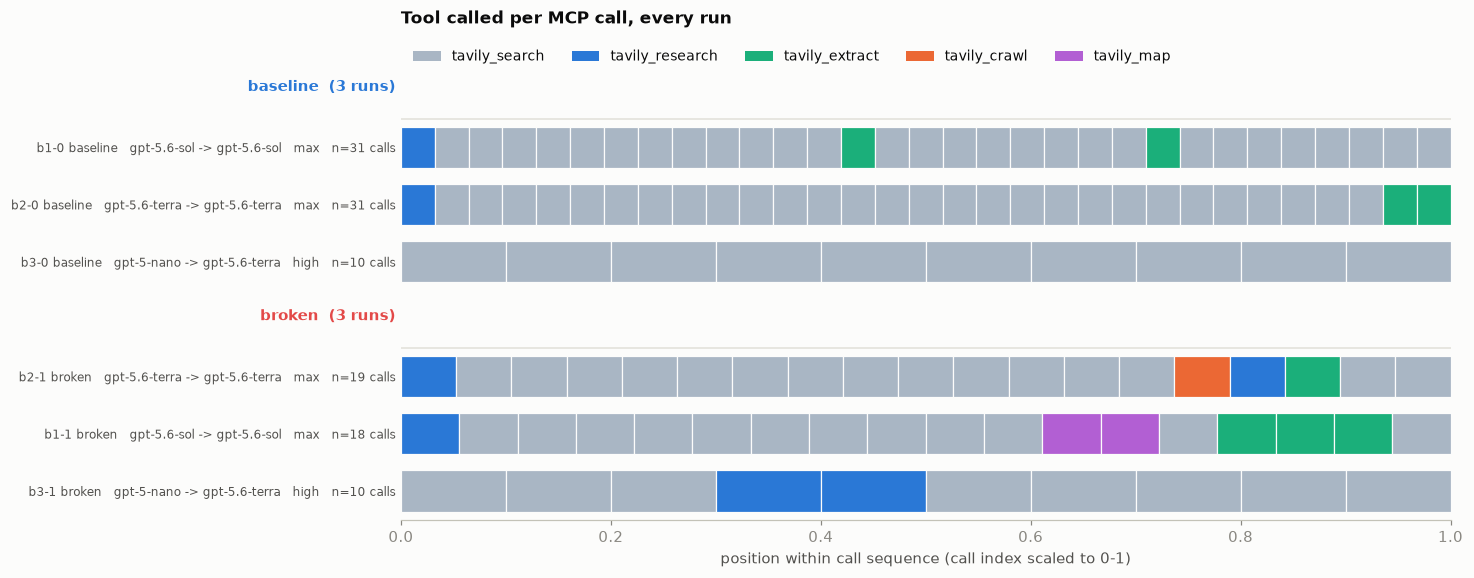

In [ ]:
def call_ribbon(ax, color_of, legend_handles, title, note=None):
    
    y, yticks, ylabels, seps = 0, [], [], []
    for cond in COND_ORDER:
        rows = list(runs[runs.condition == cond]
                    .sort_values("mcp_call_count", ascending=False).itertuples())
        seps.append((y - 0.5, cond, len(rows)))
        for r in rows:
            cl = calls[calls.run == r.run].sort_values("index")
            if len(cl):
                w = 1.0 / len(cl)
                ax.broken_barh([(j * w, w) for j in cl.j], (y - .36, .72),
                               facecolors=[color_of(c) for c in cl.itertuples()],
                               edgecolor=SURFACE, linewidth=0.8, zorder=2)
                if note:
                    txt, tc = note(r, cl)
                    if txt:
                        ax.text(1.01, y, txt, va="center", fontsize=8,
                                color=tc, fontweight="bold")
            else:
                ax.broken_barh([(0, 1)], (y - .36, .72), facecolors="none",
                               edgecolor=MUTED, linewidth=1, hatch="///", zorder=2)
                ax.text(1.01, y, "no mcp calls", va="center", fontsize=8,
                        color="#d03b3b", fontweight="bold")
            yticks.append(y)
            ylabels.append(f"{short(r.run)}   {r.agent_model} -> {r.monitor_model}   "
                           f"{r.effort}   n={int(r.mcp_call_count)} calls")
            y += 1
        y += 1
    for ypos, cond, n in seps:
        ax.axhline(ypos, color=GRID, linewidth=1, zorder=1)
        ax.text(-0.005, ypos - 0.55, f"{cond}  ({n} runs)", ha="right", va="center",
                fontsize=10, fontweight="bold", color=COND_COLOR[cond])
    ax.set_yticks(yticks); ax.set_yticklabels(ylabels, fontsize=8, color=SECOND)
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(y - 1.5, -1.2)
    ax.set_xlim(0, 1)
    ax.set_xlabel("position within call sequence (call index scaled to 0-1)")
    ax.spines["left"].set_visible(False)
    ax.set_title(title, loc="left", pad=36)
    ax.legend(handles=legend_handles, loc="lower left", bbox_to_anchor=(0, 1.005),
              ncol=5, frameon=False, fontsize=9)
    return ax

nrows = len(runs) + len(COND_ORDER)
fig, ax = plt.subplots(figsize=(13.5, 0.42 * nrows + 2.0))
call_ribbon(ax, lambda c: TOOL_COLOR[c.tool],
            [Patch(facecolor=TOOL_COLOR[t], label=t) for t in TOOL_ORDER],
            "Tool called per MCP call, every run")
plt.tight_layout(); plt.show()

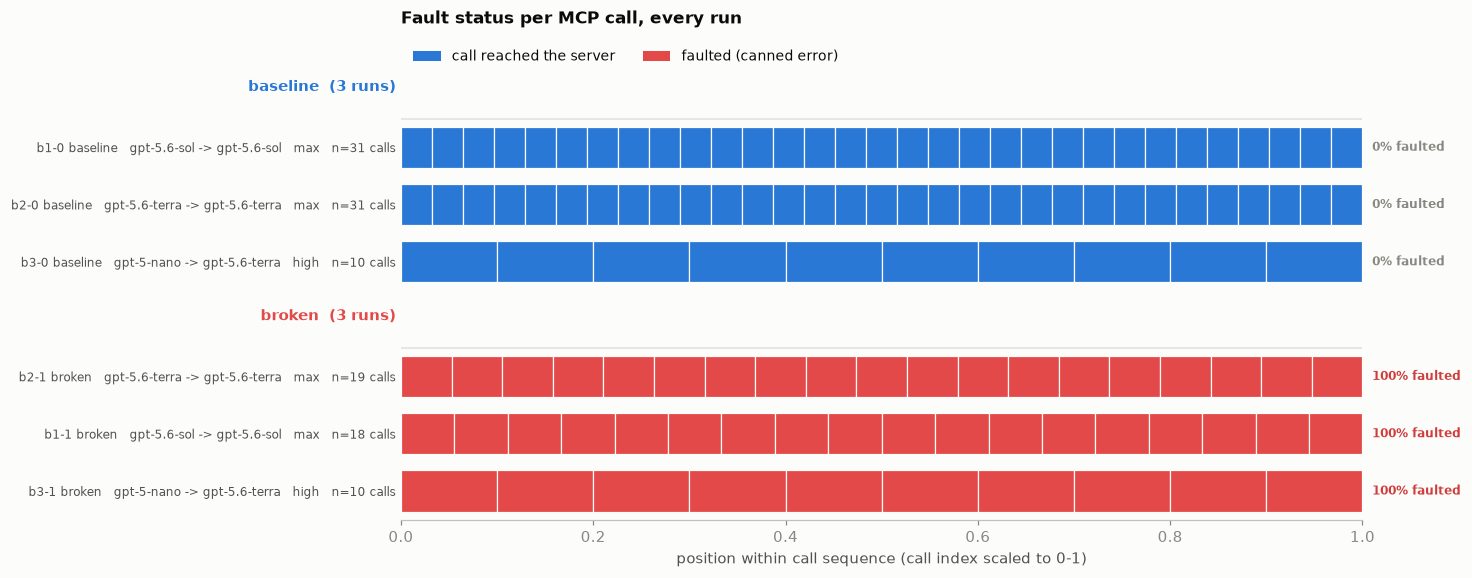

           runs  calls  faulted  faulted_share
condition                                     
baseline      3     72        0            0.0
broken        3     47       47            1.0


In [ ]:

nrows = len(runs) + len(COND_ORDER)
fig, ax = plt.subplots(figsize=(13.5, 0.42 * nrows + 2.0))
call_ribbon(ax, lambda c: FAULT_COLOR[c.faulted],
            [Patch(facecolor=FAULT_COLOR[k], label=lbl) for k, lbl in
             [(False, "call reached the server"), (True, "faulted (canned error)")]],
            "Fault status per MCP call, every run",
            note=lambda r, cl: (f"{cl.faulted.mean():.0%} faulted",
                                "#d03b3b" if cl.faulted.any() else MUTED))
plt.tight_layout(); plt.show()

print(runs.groupby("condition", observed=True)
      .agg(runs=("run", "size"), calls=("mcp_call_count", "sum"),
           faulted=("mcp_faulted_count", "sum"),
           faulted_share=("faulted_share", "mean")))